## Implementation using two different models

**1.Installing Libraries**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

**2.Generating data and spliting data**

In [10]:
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
X_train, y_train, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**3.Training the different models**

In [21]:
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train, y_train)

random_forest_model= RandomForestClassifier(n_estimators = 100, random_state=42)
random_forest_model.fit(X_train, y_train)
X=X[:200]
y=y[:200]

**4.Prediction**

In [25]:
y_pred_logistic = logistic_model.predict_proba(X_test)[:,1]
y_pred_rf = random_forest_model.predict_proba(X_test)[:,1]

**5.Creating a dataframe**

In [28]:
test_df = pd.DataFrame({'True':y_test, 'Logistic':y_pred_logistic, 'RandomForest':y_pred_rf})
print(test_df)

     True  Logistic  RandomForest
0       2  0.004848          0.12
1       1  0.727099          0.62
2       2  0.004831          0.10
3       2  0.003385          0.06
4       1  0.845308          0.65
..    ...       ...           ...
195     1  0.984140          0.89
196     0  0.036926          0.09
197     0  0.010647          0.04
198     0  0.138325          0.07
199     1  0.526905          0.73

[200 rows x 3 columns]


**Plotting ROC Curve for models**

In [33]:
fpr_log, tpr_log, _ = roc_curve(y_test, y_pred_logistic)
roc_auc_log = auc(fpr_log, tpr_log)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

ValueError: multiclass format is not supported

In [32]:
plt.figure(figsize=(7,5))

for model in ['Logistic', 'RandomForest']:
    fpr, tpr,_=roc_curve(test_df['True'], test_df[model])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model} (AUC= {roc_auc:.2f})')

plt.plot([0,1], [0,1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Two Models')
plt.legend()
plt.show()

ValueError: multiclass format is not supported

<Figure size 700x500 with 0 Axes>

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
from itertools import cycle

In [12]:
X, y = make_classification(
    n_samples=1000, n_features=20, n_classes=3, n_informative=10, random_state=42)

y_bin = label_binarize(y, classes=np.unique(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42)

In [14]:
logistic_model = OneVsRestClassifier(LogisticRegression(random_state=42))
logistic_model.fit(X_train, y_train)

rf_model = OneVsRestClassifier(
    RandomForestClassifier(n_estimators=100, random_state=42))
rf_model.fit(X_train, y_train)

OneVsRestClassifier(estimator=RandomForestClassifier(random_state=42))

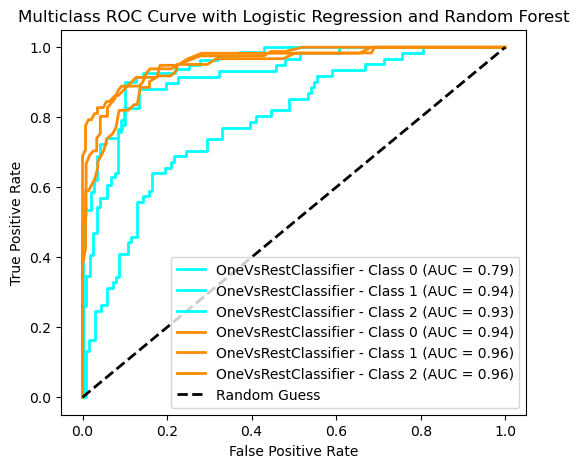

In [15]:
fpr = dict()
tpr = dict()
roc_auc = dict()

models = [logistic_model, rf_model]

plt.figure(figsize=(6, 5))
colors = cycle(['aqua', 'darkorange'])

for model, color in zip(models, colors):
    for i in range(model.classes_.shape[0]):
        fpr[i], tpr[i], _ = roc_curve(
            y_test[:, i], model.predict_proba(X_test)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'{model.__class__.__name__} - Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve with Logistic Regression and Random Forest')
plt.legend(loc="lower right")
plt.show()